In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows",200)
sns.set_style("whitegrid")

In [2]:
#Loading the data
train=pd.read_csv("input/train.csv")
test=pd.read_csv("input/test.csv")
sub=pd.read_csv("input/sample_submission.csv")

#This is to check the shape of the data and the columns in each dataset
print("train:", train.shape, "|test:", test.shape)
print("submission columns:", list(sub.columns))
print("columns in train but not in test:", set(train.columns) - set(test.columns))
print("columns in test but not in train:", set(test.columns) - set(train.columns))
train.head()

train: (171202, 34) |test: (61500, 33)
submission columns: ['SK_ID_CURR', 'TARGET']
columns in train but not in test: {'TARGET'}
columns in test but not in train: set()


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,Married,House / apartment,0.010032,-9233,-878,-333.0,-522,NaN,1,1,1,Core staff,2.0,2,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,Married,House / apartment,0.008019,-20148,365243,-4469.0,-3436,NaN,1,0,0,Other,2.0,2,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,Married,House / apartment,0.004960,-18496,-523,-3640.0,-2050,NaN,1,1,1,Core staff,2.0,2,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,Widow,House / apartment,0.005002,-24177,365243,-4950.0,-3951,NaN,1,0,0,Other,1.0,3,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,Married,With parents,0.006296,-10685,-697,-5101.0,-3226,NaN,1,1,1,Drivers,2.0,3,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


In [3]:
#Target balance
print(train["TARGET"].value_counts(normalize=True))

#Types
print(train.dtypes.value_counts())

#Missing values
miss=(train.isna().mean()*100).sort_values(ascending=False)
print(miss[miss>0].head(30))

#Duplicates and ID uniqueness 
print("duplicate rows: ", train.duplicated().sum())

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64
float64    16
int64      10
str         8
Name: count, dtype: int64
EXT_SOURCE_1                  69.466478
OWN_CAR_AGE                   65.999229
EXT_SOURCE_3                  31.883973
AMT_REQ_CREDIT_BUREAU_MON     13.502179
AMT_REQ_CREDIT_BUREAU_QRT     13.502179
AMT_REQ_CREDIT_BUREAU_HOUR    13.502179
AMT_REQ_CREDIT_BUREAU_YEAR    13.502179
EXT_SOURCE_2                   0.215535
CNT_FAM_MEMBERS                0.001168
dtype: float64
duplicate rows:  0


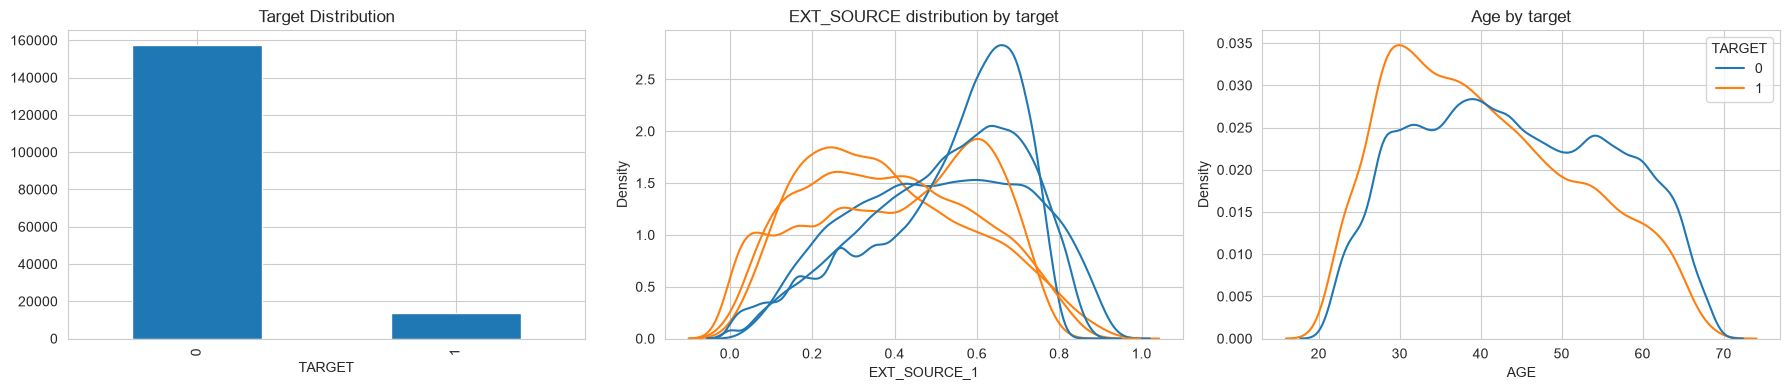

In [4]:
fig, ax=plt.subplots(1,3,figsize=(18,4))

train["TARGET"].value_counts().plot.bar(ax=ax[0], title="Target Distribution")

#Default rate by missingness of EXT_SOURCE features
ext=[c for c in train.columns if c.startswith("EXT_SOURCE")]
for c in ext:
    sns.kdeplot(data=train, x=c, hue="TARGET", common_norm=False, ax=ax[1], legend=False)
ax[1].set_title("EXT_SOURCE distribution by target")

#Age distribution by target
train["AGE"]=-train["DAYS_BIRTH"]/365
sns.kdeplot(data=train, x="AGE", hue="TARGET", common_norm=False, ax=ax[2]) 
ax[2].set_title("Age by target") 
plt.tight_layout(); plt.show()  

In [5]:
#Anomaly check: DAYS_EMPLOYED
print(train["DAYS_EMPLOYED"].describe())
print("placeholder rows:", (train["DAYS_EMPLOYED"]==365243).sum())
print(train.groupby(train["DAYS_EMPLOYED"]==365243)["TARGET"].mean())


# Corelation with target (numeric only)

corr=train.select_dtypes("number").corr()["TARGET"].drop("TARGET")
# print(train.groupby(c)["TARGET"].agg(["mean", "count"]).sort_values("mean", ascending=False), "\n")
print("Strongest Negative Correlations (lower risk):\n", corr.sort_values().head(5))
print("\nStrongest Positive Correlations (higher risk):\n", corr.sort_values().tail(5))

count    171202.000000
mean      63960.411969
std      141401.513149
min      -17912.000000
25%       -2772.000000
50%       -1215.000000
75%        -288.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64
placeholder rows: 30898
DAYS_EMPLOYED
False    0.086562
True     0.054243
Name: TARGET, dtype: float64
Strongest Negative Correlations (lower risk):
 EXT_SOURCE_3    -0.178317
EXT_SOURCE_2    -0.162562
EXT_SOURCE_1    -0.154050
AGE             -0.079541
DAYS_EMPLOYED   -0.044592
Name: TARGET, dtype: float64

Strongest Positive Correlations (higher risk):
 FLAG_EMP_PHONE            0.045646
DAYS_ID_PUBLISH           0.052567
DAYS_LAST_PHONE_CHANGE    0.055194
REGION_RATING_CLIENT      0.058984
DAYS_BIRTH                0.079541
Name: TARGET, dtype: float64


In [6]:
for c in ["AMT_INCOME_TOTAL","AMT_CREDIT", "DAYS_BIRTH"]:
    print(c,"train mean:", round(train[c].mean(), 1), "|test mean:", round(test[c].mean(), 1))

AMT_INCOME_TOTAL train mean: 168371.2 |test mean: 169549.4
AMT_CREDIT train mean: 599129.3 |test mean: 595668.2
DAYS_BIRTH train mean: -16045.3 |test mean: -15915.2


In [7]:
def fe(df):
    df = df.copy()
    # anomaly fix
    df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
    df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)

    # age and time ratios
    df["AGE"] = -df["DAYS_BIRTH"] / 365
    df["EMPLOYED_AGE"] = df["DAYS_EMPLOYED"] / df["DAYS_BIRTH"]
    df["REG_AGE"] = df["DAYS_REGISTRATION"] / df["DAYS_BIRTH"]
    df["ID_PUBLISH_AGE"] = df["DAYS_ID_PUBLISH"] / df["DAYS_BIRTH"]

    # money ratios
    df["CREDIT_INCOME"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
    df["ANNUITY_INCOME"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
    df["CREDIT_TERM"] = df["AMT_CREDIT"] / df["AMT_ANNUITY"]   # loan length proxy
    df["CREDIT_GOODS"] = df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"]
    df["GOODS_DIFF"] = df["AMT_CREDIT"] - df["AMT_GOODS_PRICE"]
    fam = df["CNT_FAM_MEMBERS"].replace(0, np.nan)
    df["INCOME_PER_PERSON"] = df["AMT_INCOME_TOTAL"] / fam

    # external scores
    ext = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
    df["EXT_MEAN"] = df[ext].mean(axis=1)
    df["EXT_MIN"] = df[ext].min(axis=1)
    df["EXT_MAX"] = df[ext].max(axis=1)
    df["EXT_PROD"] = df[ext].prod(axis=1)
    df["EXT_STD"] = df[ext].std(axis=1)
    df["EXT_2_3"] = df["EXT_SOURCE_2"] * df["EXT_SOURCE_3"]
    df["EXT_MISSING"] = df[ext].isna().sum(axis=1)

    # bureau enquiries and general missingness
    bur = [c for c in df if c.startswith("AMT_REQ_CREDIT_BUREAU")]
    df["BUREAU_TOTAL"] = df[bur].sum(axis=1)
    df["N_MISSING"] = df.isna().sum(axis=1)

    return df.replace([np.inf, -np.inf], np.nan)

In [8]:
# 1. Check OWN_CAR_AGE missingness directly
if "FLAG_OWN_CAR" in train.columns:
    print(pd.crosstab(train["FLAG_OWN_CAR"], train["OWN_CAR_AGE"].isna()))
else:
    print("OWN_CAR_AGE missing count:", train["OWN_CAR_AGE"].isna().sum())

# 2. Default rate by EXT_SOURCE missingness
for c in [c for c in train.columns if c.startswith("EXT_SOURCE")]:
    print(c)
    print(train.groupby(train[c].isna())["TARGET"].agg(["mean", "count"]), "\n")

# 3. Adversarial validation: can a model tell train from test?
import lightgbm as lgb
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score
import numpy as np

feats = [c for c in test.columns if c != "SK_ID_CURR"]
adv = pd.concat([train[feats], test[feats]], ignore_index=True)

for c in adv.select_dtypes("object"):
    adv[c] = adv[c].astype("category")

lab = np.r_[np.zeros(len(train)), np.ones(len(test))]

p = cross_val_predict(
    lgb.LGBMClassifier(n_estimators=200, verbose=-1, random_state=42),
    adv,
    lab,
    cv=5,
    method="predict_proba"
)[:, 1]

print("Adversarial AUC:", round(roc_auc_score(lab, p), 4))  # ~0.50 means train and test are identical

OWN_CAR_AGE missing count: 112992
EXT_SOURCE_1
                  mean   count
EXT_SOURCE_1                  
False         0.074875   52274
True          0.083303  118928 

EXT_SOURCE_2
                  mean   count
EXT_SOURCE_2                  
False         0.080734  170833
True          0.078591     369 

EXT_SOURCE_3
                  mean   count
EXT_SOURCE_3                  
False         0.077056  116616
True          0.088576   54586 



C:\Users\User-Home\AppData\Local\Temp\ipykernel_35056\1053454638.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in adv.select_dtypes("object"):


Adversarial AUC: 0.5122


In [9]:
#This Cell is to check the performance of the model with and without engineered features. The function prep() prepares the data for modeling by dropping unnecessary columns and encoding categorical variables. The function run_cv() performs cross-validation using LightGBM and returns the AUC score, out-of-fold predictions, test predictions, and the trained model.
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

y = train["TARGET"]
drop = ["SK_ID_CURR", "TARGET"]

train = pd.read_csv("input/train.csv")
test = pd.read_csv("input/test.csv")
y = train["TARGET"]

def prep(tr, te):
    tr = tr.drop(columns=[c for c in drop if c in tr])
    te = te.drop(columns=[c for c in drop if c in te])
    te = te[tr.columns]  # same columns, same order, or it errors loudly
    for c in tr.select_dtypes(exclude="number").columns:
        cats = pd.concat([tr[c], te[c]]).astype("category").cat.categories
        tr[c] = pd.Categorical(tr[c], categories=cats)
        te[c] = pd.Categorical(te[c], categories=cats)
    return tr, te

def run_cv(X, T, seed=42):
    oof, pred = np.zeros(len(X)), np.zeros(len(T))
    for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y):
        m = lgb.LGBMClassifier(n_estimators=5000, learning_rate=0.03, num_leaves=31,
                               colsample_bytree=0.6, subsample=0.8, subsample_freq=1, verbose=-1)
        m.fit(X.iloc[tr_i], y.iloc[tr_i], eval_set=[(X.iloc[va_i], y.iloc[va_i])],
              eval_metric="auc", callbacks=[lgb.early_stopping(200, verbose=False)])
        oof[va_i] = m.predict_proba(X.iloc[va_i])[:, 1]
        pred += m.predict_proba(T)[:, 1] / 5
    return roc_auc_score(y, oof), oof, pred, m

# A: raw columns only (after the DAYS_EMPLOYED fix)
Xa, Ta = prep(train, test)
Xa["DAYS_EMPLOYED"] = Xa["DAYS_EMPLOYED"].replace(365243, np.nan)
Ta["DAYS_EMPLOYED"] = Ta["DAYS_EMPLOYED"].replace(365243, np.nan)
auc_a, *_ = run_cv(Xa, Ta)

# B: with engineered features
Xb, Tb = prep(fe(train), fe(test))
auc_b, oof_b, pred_b, m_b = run_cv(Xb, Tb)

print(f"A raw: {auc_a:.4f} | B engineered: {auc_b:.4f}")
imp = pd.Series(m_b.feature_importances_, Xb.columns).sort_values(ascending=False)
print(imp.head(15))

C:\Users\User-Home\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\User-Home\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\User-Home\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\User-Home\AppData\Roaming\Python\Python313\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_

A raw: 0.7503 | B engineered: 0.7582
CREDIT_TERM               1389
ORGANIZATION_TYPE         1380
EXT_SOURCE_3               873
EXT_STD                    834
DAYS_EMPLOYED              787
DAYS_REGISTRATION          781
EMPLOYED_AGE               767
DAYS_LAST_PHONE_CHANGE     759
DAYS_ID_PUBLISH            748
ID_PUBLISH_AGE             711
REG_AGE                    682
CREDIT_INCOME              665
EXT_MEAN                   663
AGE                        656
ANNUITY_INCOME             652
dtype: int32


EXT_MEAN                  0.1720
CREDIT_TERM               0.0613
ORGANIZATION_TYPE         0.0513
EXT_2_3                   0.0404
EXT_MAX                   0.0364
EXT_MIN                   0.0323
EXT_SOURCE_3              0.0320
DAYS_EMPLOYED             0.0278
CREDIT_GOODS              0.0270
EXT_STD                   0.0266
EMPLOYED_AGE              0.0252
DAYS_LAST_PHONE_CHANGE    0.0229
dtype: float64


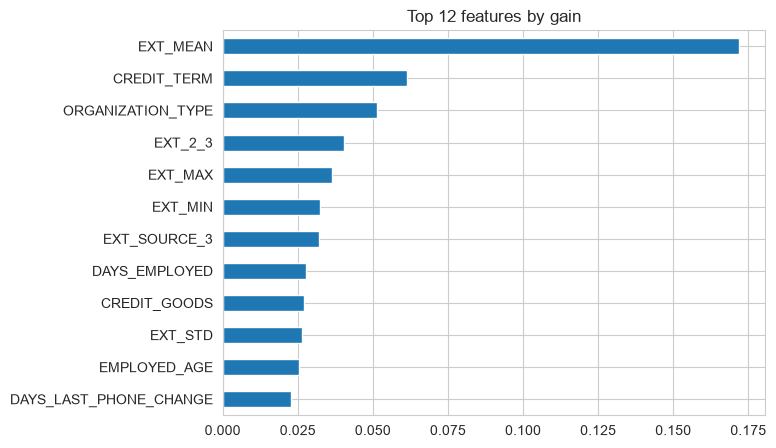

In [10]:
#THIS CELL IS TO CHECK THE FEATURE IMPORTANCE OF THE MODEL. The feature importance is calculated using the gain metric, which measures the contribution of each feature to the model's performance. The top 12 features are displayed in a horizontal bar chart.
imp_gain = pd.Series(m_b.booster_.feature_importance(importance_type="gain"), Xb.columns)
imp_gain = (imp_gain / imp_gain.sum()).sort_values(ascending=False)
top = imp_gain.head(12)
print(top.round(4))
top.sort_values().plot.barh(figsize=(7, 5), title="Top 12 features by gain")
plt.show()

In [11]:
import os
out = sub[["SK_ID_CURR"]].merge(
    pd.DataFrame({"SK_ID_CURR": test["SK_ID_CURR"], "TARGET": pred_b}),
    on="SK_ID_CURR", how="left")
assert out["TARGET"].notna().all() and len(out) == len(sub)
os.makedirs("output", exist_ok=True)
out.to_csv("output/submission.csv", index=False)
print(out.head())

   SK_ID_CURR    TARGET
0      171202  0.029912
1      171203  0.185115
2      171204  0.143450
3      171205  0.102243
4      171206  0.194760


In [ ]:
chk = pd.read_csv("output/submission.csv")
ref = pd.read_csv("input/sample_submission.csv")
print("shape:", chk.shape, "| expected:", ref.shape)
print("columns match:", list(chk.columns) == list(ref.columns))
print("IDs match, same order:", chk["SK_ID_CURR"].equals(ref["SK_ID_CURR"]))
print("missing:", chk["TARGET"].isna().sum(), "| min/max:", chk["TARGET"].min().round(4), chk["TARGET"].max().round(4))
print("mean prediction:", chk["TARGET"].mean().round(4), "(should be near 0.08)")